# Phase 4 · 3/3 — Predicting churn with Machine Learning

**VIGIE · Group BI 5** — Raed Meddeb · Ibrahim Grira · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Integrated Project, ESPRIT School of Business · Supervisors: Aymen Ben Brik and Hela Hammami

---

**Question.** From a customer's profile, can we estimate their probability of leaving?

| Step | Content |
|---|---|
| 1 | Grain and target |
| 2 | **Target leakage check** |
| 3 | Features kept |
| 4 | Split per customer, with no contamination |
| 5 | Comparison of three models |
| 6 | Hyperparameter tuning |
| 7 | Sensitivity analysis: what is each family of features worth? |
| 8 | Calibration and gains curve |
| 9 | Interpretability: importance and SHAP values |
| 10 | Final model, limitations, export |

The model code is in `04_machine_learning/src/churn.py`; this notebook runs it and comments on the results.
*No customer row is displayed.*

In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "04_machine_learning" / "src"))
sys.path.insert(0, str(ROOT / "05_web_app"))
import churn
import export_app
from utils import preprocessing            # 05_web_app/utils: the same code as the application
from vigie import config, data, features, style

warnings.filterwarnings("ignore")
style.apply()
C = config.COLORS
n = style.thousands

df = data.load()
accounts = data.account_grain(df)
customers = data.customer_grain(df, accounts)
ref_date = data.reference_date(df)

## 1. Grain and target

**Grain: the customer.** One row = one customer holding at least one account.

**Target: `CHURN = 1` if all of the customer's accounts are closed.** It follows from the project definition
(`ACCOUNT_STATUS = "Closed"`). Since no customer holds both an active and a closed account, this target is
unambiguous.

**Why the customer rather than the account?** The only usable features are characteristics of the *customer*
(see the leakage check below). At account grain, a customer with three accounts would give three identical rows
with the same target: they would weigh three times without bringing any information. The customer grain avoids
this bias.

In [2]:
profiles, X, y, groups = features.modelling_set(customers, ref_date)
breakdown = pd.Series({
    "Customers in scope (at least one account)": len(y),
    "Customers who stayed (CHURN = 0)": int((y == 0).sum()),
    "Customers who left (CHURN = 1)": int((y == 1).sum()),
}, name="Count").to_frame()
breakdown["Share"] = (breakdown["Count"] / len(y)).map("{:.1%}".format)
display(breakdown)
mixed = int((accounts.groupby("CUSTOMER_NO")["CHURN"].nunique() > 1).sum())
print("Customers holding both an active and a closed account:", mixed)

,Count,Share
Customers in scope (at least one account),319040,100.0%
Customers who stayed (CHURN = 0),201695,63.2%
Customers who left (CHURN = 1),117345,36.8%


Customers holding both an active and a closed account: 0


**Imbalance.** 36.8% of customers left: the imbalance is **moderate**. We apply **no rebalancing** (neither
over-sampling nor class weighting). Two reasons: (1) rebalancing distorts the predicted probabilities, which the
application displays as they are; (2) the precision / recall trade-off is set more simply, and transparently,
through the **decision threshold** (section 5).

## 2. Target leakage check

The file is a snapshot taken **after** the closures. Some columns do not *predict* the closure: they *record* it.
Using them would give a model that looks perfect and is useless in practice, since that information does not exist
as long as the customer has not left.

### 2.1 Blank test: is a blank column enough to guess the target?

For each column, the target is predicted with **a single flag: "the value is missing"**, and the resulting AUC
is measured. A sound column gives 0.5 (the blank teaches nothing).

,% blank if active,% blank if closed,Blank AUC,Verdict
Variable,,,,
ACCT_CLOSE_DATE,100.0,0.0,1.000,LEAK — excluded
CLOSURE_REASON,100.0,9.1,0.954,LEAK — excluded
CURRENCY,0.0,67.8,0.839,LEAK — excluded
ACCOUNT_CATEGORY,0.0,67.8,0.839,LEAK — excluded
ACCT_OPENING_DATE,0.0,67.8,0.839,LEAK — excluded
ACCOUNT_TYPE_DESC,0.0,67.8,0.839,LEAK — excluded
ACCT_BALANCE,0.0,67.8,0.839,LEAK — excluded
AMOUNT,15.0,77.7,0.813,LEAK — excluded
PRODUCT_LINE,14.7,76.0,0.806,LEAK — excluded


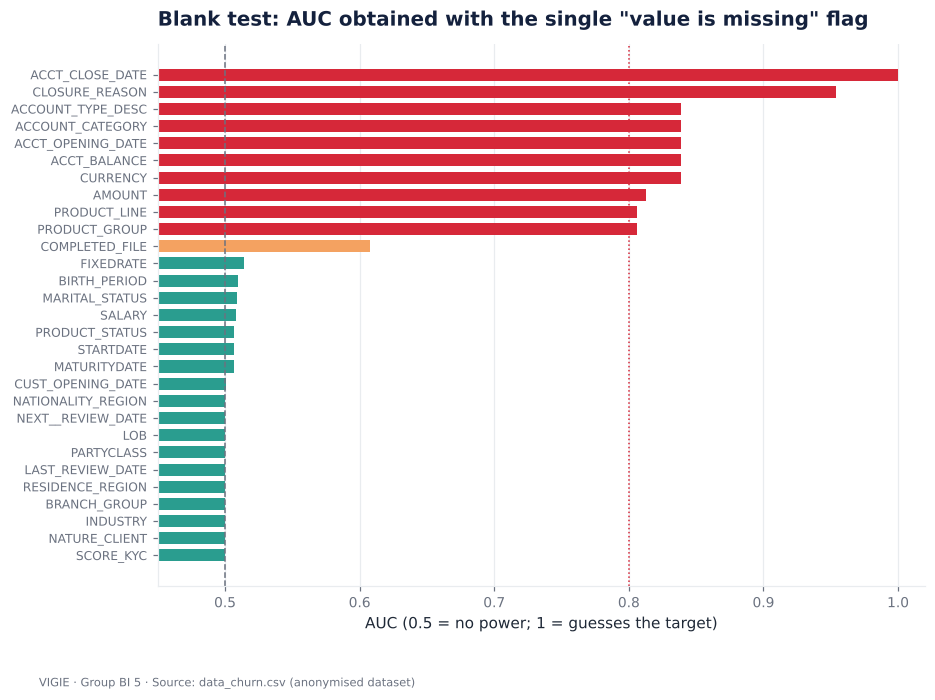

In [3]:
account_table = accounts.merge(customers[data.CUSTOMER_COLUMNS], on="CUSTOMER_NO", suffixes=("", "_CUSTOMER"))
tested_columns = [c for c in df.columns if c not in ("CUSTOMER_NO", "ACCOUNT_NO", "ACCOUNT_STATUS")]
audit = churn.leakage_audit(account_table, "CHURN", tested_columns)
display(audit)

fig, ax = plt.subplots(figsize=(9, 6.4))
a = audit["Blank AUC"].sort_values()
colors = [C["churn"] if v >= 0.8 else C["amber"] if v >= 0.6 else C["retention"] for v in a]
ax.barh(a.index, a, color=colors, height=0.7)
ax.axvline(0.5, color=C["grey"], ls="--", lw=1)
ax.axvline(0.8, color=C["churn"], ls=":", lw=1)
ax.set_xlim(0.45, 1.02)
ax.set_title("Blank test: AUC obtained with the single \"value is missing\" flag")
ax.set_xlabel("AUC (0.5 = no power; 1 = guesses the target)")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
style.save(fig, "04_leakage_blank_test")
plt.show()

### 2.2 Category test: do some values point to the closure?

The blank test does not see everything. `PRODUCT_STATUS` is blank as often for active accounts as for closed
ones, but some of its **values** describe the closure itself.

In [4]:
product_status = (accounts.groupby(accounts["PRODUCT_STATUS"].fillna("(blank)"))["CHURN"]
                  .agg(Accounts="size", Closure_rate="mean").sort_values("Closure_rate", ascending=False))
product_status = product_status[product_status["Accounts"] >= config.MIN_CELL_SIZE]
display(product_status.style.format({"Accounts": n, "Closure_rate": "{:.1%}"}))

,Accounts,Closure_rate
PRODUCT_STATUS,,
CLOSE,220,99.1%
UNAUTH,"1,685",86.6%
PENDING.CLOSURE,"1,480",78.2%
AUTH,302,77.5%
(blank),"367,453",36.5%
CURRENT,"35,927",28.8%
EXPIRED,"3,239",23.2%


### 2.3 Demonstration: what a model "with leakage" gives

We deliberately add to the model three features built on the suspicious columns — the share of the customer's
accounts whose balance, account family and product are blank — and compare.

In [5]:
leak = accounts.assign(BLANK_BALANCE=accounts["ACCT_BALANCE"].isna(), BLANK_FAMILY=accounts["ACCOUNT_CATEGORY"].isna(),
                       BLANK_PRODUCT=accounts["PRODUCT_GROUP"].isna())
leak = leak.groupby("CUSTOMER_NO")[["BLANK_BALANCE", "BLANK_FAMILY", "BLANK_PRODUCT"]].mean()
X_leak = X.copy()
for col in leak.columns:
    X_leak[f"LEAK_{col}"] = leak[col].reindex(groups).to_numpy()

parts = churn.split(y, groups)
tr, va, te = parts["train"], parts["validation"], parts["test"]
with_leak = churn.xgboost().fit(X_leak.iloc[tr], y[tr])
without_leak = churn.xgboost().fit(X.iloc[tr], y[tr])
demo = pd.DataFrame({
    "ROC-AUC on the test set": [roc_auc_score(y[te], with_leak.predict_proba(X_leak.iloc[te])[:, 1]),
                                roc_auc_score(y[te], without_leak.predict_proba(X.iloc[te])[:, 1])],
}, index=["Model WITH leaking features", "Model WITHOUT leaking features (kept)"])
display(demo.round(4))

,ROC-AUC on the test set
Model WITH leaking features,0.9511
Model WITHOUT leaking features (kept),0.7507


**Reading — leakage check.**

| Verdict | Columns | Decision |
|---|---|---|
| **Certain leak** (blank AUC ≥ 0.80) | `ACCT_CLOSE_DATE`, `CLOSURE_REASON`, `ACCT_BALANCE`, `ACCT_OPENING_DATE`, `ACCOUNT_CATEGORY`, `ACCOUNT_TYPE_DESC`, `CURRENCY`, `AMOUNT`, `PRODUCT_GROUP`, `PRODUCT_LINE` | **Excluded**, together with any derived feature (account age, product diversity, blank-balance flag…) |
| **Leak through the values** | `PRODUCT_STATUS` (`CLOSE`: 99% closures; `UNAUTH`: 87%; `PENDING.CLOSURE`: 78%) | **Excluded** |
| **No predictive value of their own** | `STARTDATE`, `MATURITYDATE`, `FIXEDRATE` (≈ 90% blank, product attributes) | Not kept |
| **To watch** (blank AUC 0.61) | `COMPLETED_FILE` | Kept: it is a characteristic of the *customer*, recommended by the guide. Its weight is measured separately (section 7) |
| **Sound** | every other customer characteristic | Kept |

The demonstration is conclusive: adding three blank flags is enough for the AUC to jump from 0.75 to **0.95**.
**This is not a good model, it is a model that reads the answer**: these blanks only appear once the account is
closed. Without them the AUC is 0.75: this is the true level of what a customer's profile lets us anticipate.

The description document had warned that the account family, the currency and the amount "could follow the same
pattern" as the balance: the blank test **confirms** it, and extends it to the account opening date.

## 3. Features kept

Twelve features, all known **before** a possible departure, in three families.

In [6]:
origin = {
    "AGE": ("BIRTH_PERIOD", "reference date − middle of the birth band"),
    "MARITAL_STATUS": ("MARITAL_STATUS", "blank → \"NR\""),
    "RESIDENCE_ZONE": ("RESIDENCE_REGION", "rare categories grouped"),
    "CUSTOMER_TENURE": ("CUST_OPENING_DATE", "years since the start of the relationship"),
    "N_ACCOUNTS": ("ACCOUNT_NO", "number of distinct accounts of the customer"),
    "CUSTOMER_TYPE": ("NATURE_CLIENT", "TRPP / TRPM → \"OTHER\""),
    "SEGMENT": ("PARTYCLASS", "—"),
    "SALARY": ("SALARY", "the blank is kept (not declared)"),
    "KYC_SCORE": ("SCORE_KYC", "blank → \"NR\""),
    "FILE_COMPLETE": ("COMPLETED_FILE", "YES → 1, blank → 0"),
    "MONTHS_SINCE_REVIEW": ("LAST_REVIEW_DATE", "months elapsed since the last review"),
    "MONTHS_TO_NEXT_REVIEW": ("NEXT__REVIEW_DATE", "months left (negative = review overdue)"),
}
rows = []
for family, names in features.feature_families().items():
    for name in names:
        rows.append({"Family": family, "Feature": name, "Label": preprocessing.LABELS[name],
                     "Source column": origin[name][0], "Construction": origin[name][1],
                     "Type": "Numeric" if name in preprocessing.NUMERIC else "Categorical",
                     "% missing": f"{profiles[name].isna().mean():.1%}" if name in preprocessing.NUMERIC else "—"})
display(pd.DataFrame(rows).set_index(["Family", "Feature"]))
print(f"Model matrix: {X.shape[0]:,} customers × {X.shape[1]} columns "
      f"({len(preprocessing.NUMERIC)} numeric + {X.shape[1] - len(preprocessing.NUMERIC)} indicator columns).")

Label  \
Family       Feature                                           
Demographics AGE                                         Age   
             MARITAL_STATUS                   Marital status   
             RESIDENCE_ZONE                   Residence zone   
Relationship CUSTOMER_TENURE         Customer tenure (years)   
             N_ACCOUNTS                   Number of accounts   
             CUSTOMER_TYPE                     Customer type   
             SEGMENT                      Commercial segment   
             SALARY                          Declared income   
Compliance   KYC_SCORE                             KYC score   
             FILE_COMPLETE                     Complete file   
             MONTHS_SINCE_REVIEW    Months since last review   
             MONTHS_TO_NEXT_REVIEW     Months to next review   

                                        Source column  \
Family       Feature                                    
Demographics AGE                         BIRTH_PERIOD   
             MARITAL_STATUS            MARITAL_STATUS   
             RESIDENCE_ZONE          RESIDENCE_REGION   
Relationship CUSTOMER_TENURE        CUST_OPENING_DATE   
             N_ACCOUNTS                    ACCOUNT_NO   
             CUSTOMER_TYPE              NATURE_CLIENT   
             SEGMENT                       PARTYCLASS   
             SALARY                            SALARY   
Compliance   KYC_SCORE                      SCORE_KYC   
             FILE_COMPLETE             COMPLETED_FILE   
             MONTHS_SINCE_REVIEW     LAST_REVIEW_DATE   
             MONTHS_TO_NEXT_REVIEW  NEXT__REVIEW_DATE   

                                                                   Construction  \
Family       Feature                                                              
Demographics AGE                      reference date − middle of the birth band   
             MARITAL_STATUS                                        blank → "NR"   
             RESIDENCE_ZONE                             rare categories grouped   
Relationship CUSTOMER_TENURE          years since the start of the relationship   
             N_ACCOUNTS             number of distinct accounts of the customer   
             CUSTOMER_TYPE                                TRPP / TRPM → "OTHER"   
             SEGMENT                                                          —   
             SALARY                            the blank is kept (not declared)   
Compliance   KYC_SCORE                                             blank → "NR"   
             FILE_COMPLETE                                   YES → 1, blank → 0   
             MONTHS_SINCE_REVIEW           months elapsed since the last review   
             MONTHS_TO_NEXT_REVIEW      months left (negative = review overdue)   

                                           Type % missing  
Family       Feature                                       
Demographics AGE                        Numeric      6.3%  
             MARITAL_STATUS         Categorical         —  
             RESIDENCE_ZONE         Categorical         —  
Relationship CUSTOMER_TENURE            Numeric      0.6%  
             N_ACCOUNTS                 Numeric      0.0%  
             CUSTOMER_TYPE          Categorical         —  
             SEGMENT                Categorical         —  
             SALARY                     Numeric     67.3%  
Compliance   KYC_SCORE              Categorical         —  
             FILE_COMPLETE              Numeric      0.0%  
             MONTHS_SINCE_REVIEW        Numeric      0.0%  
             MONTHS_TO_NEXT_REVIEW      Numeric      0.0%

Model matrix: 319,040 customers × 31 columns (7 numeric + 24 indicator columns).


In [7]:
# Are the two review features independent? We measure the gap between the last and the next review.
scope = customers[customers["CHURN"].notna()]
cycle = ((scope["NEXT__REVIEW_DATE"] - scope["LAST_REVIEW_DATE"]).dt.days / 30.4375).round()
cycle_by_kyc = (pd.DataFrame({"KYC score": scope["SCORE_KYC"], "cycle": cycle}).dropna()
                .groupby("KYC score")["cycle"].agg(Customers="size", Most_frequent_cycle=lambda s: int(s.mode().iloc[0]),
                                                   Share_of_customers=lambda s: (s == s.mode().iloc[0]).mean()))
display(cycle_by_kyc.style.format({"Customers": n, "Most_frequent_cycle": "{} months", "Share_of_customers": "{:.1%}"}))
print(cycle_by_kyc.round(3).to_string())

,Customers,Most_frequent_cycle,Share_of_customers
KYC score,,,
H1,"17,169",24 months,97.2%
H2,"9,795",24 months,96.8%
H3,"4,099",24 months,96.9%
LR,"256,254",48 months,98.7%
MR,"31,643",36 months,97.7%


           Customers  Most_frequent_cycle  Share_of_customers
KYC score                                                    
H1             17169                   24               0.972
H2              9795                   24               0.968
H3              4099                   24               0.969
LR            256254                   48               0.987
MR             31643                   36               0.977


**A useful finding: the review cycle is set by the KYC score** — 48 months for low risk (`LR`), 36 months for
medium risk (`MR`), 24 months for the high risks (`H1` to `H3`), for 97 to 99% of customers. The two review
features are therefore not independent: *months to next review = cycle − months since last review*. We keep
both, because the second one gives the most telling piece of information directly — is the review **overdue**? —
without the model having to rebuild it. Consequence for the application: the form only asks for the date of the
last review and **derives** the next one, which makes it impossible to enter an inconsistent profile.

**Features left out by choice** (and not for leakage):

* `LOB`: strictly equivalent to `PARTYCLASS` (Cramér's V = 1); `NATIONALITY_REGION`: strongly linked to residence.
* `INDUSTRY` and `BRANCH_GROUP`: tested in section 7, they bring almost nothing; leaving them out gives a simpler
  model and a shorter form in the application.

**A single piece of encoding code.** Turning a profile into features is done by
`05_web_app/utils/preprocessing.py`, imported here. The application uses the same file: what the model learns and
what it is shown afterwards are built in the same way.

## 4. Split per customer, with no contamination

`GroupShuffleSplit` with `CUSTOMER_NO` as the group: a customer is entirely in a single set.

In [8]:
plan = pd.DataFrame({
    "Role": ["Learning", "Choice of the decision threshold", "Final evaluation (never used before)"],
    "Customers": [len(tr), len(va), len(te)],
    "Share": [f"{len(i) / len(y):.0%}" for i in (tr, va, te)],
    "Churn rate": [f"{y[i].mean():.1%}" for i in (tr, va, te)],
}, index=["Training", "Validation", "Test"])
display(plan)
shared = {f"{a} ∩ {b}": len(set(groups[parts[a]]) & set(groups[parts[b]]))
          for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]}
print("Customers shared between two sets:", shared)

,Role,Customers,Share,Churn rate
Training,Learning,223328,70%,36.7%
Validation,Choice of the decision threshold,47856,15%,36.9%
Test,Final evaluation (never used before),47856,15%,36.9%


Customers shared between two sets: {'train ∩ validation': 0, 'train ∩ test': 0, 'validation ∩ test': 0}


No customer is shared between two sets, and the churn rate is the same in all three: the split is clean and
representative.

## 5. Comparison of three models

| Model | Principle | Interest |
|---|---|---|
| Baseline | predicts the average rate for everyone | floor: every model must do better |
| **Logistic regression** | weighted sum of the features | simple, linear, readable |
| **Random Forest** | average of 300 independent trees | captures non-linearity, robust |
| **XGBoost** | trees built one after the other, each correcting the previous one | often the best performer on tabular data; handles missing values natively |

For the logistic regression and the forest, missing values are replaced by the median (computed on the training
set) and a "value is missing" flag is added. XGBoost handles missing values itself.

**Decision threshold.** Each model outputs a probability. The threshold that turns this probability into
"at risk / not at risk" is chosen on the **validation** set (the one that maximises F1), then applied as is to
the test set.

In [9]:
fitted, probas, results = {}, {}, {}
for name, model in churn.models().items():
    model.fit(X.iloc[tr], y[tr])
    p_va, p_te = model.predict_proba(X.iloc[va])[:, 1], model.predict_proba(X.iloc[te])[:, 1]
    threshold = 0.5 if name.startswith("Baseline") else churn.f1_threshold(y[va], p_va)
    fitted[name], probas[name], results[name] = model, p_te, churn.evaluate(y[te], p_te, threshold)
comparison = pd.DataFrame(results).T
metric_columns = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1", "Accuracy", "Brier", "Threshold"]
display(comparison[metric_columns].astype(float).round(3))
print(comparison[metric_columns].astype(float).round(4).to_string())

,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
Baseline (average rate),0.500,0.369,0.000,0.000,0.000,0.631,0.233,0.500
Logistic regression,0.686,0.538,0.518,0.675,0.586,0.648,0.209,0.339
Random Forest,0.748,0.607,0.515,0.813,0.630,0.649,0.193,0.299
XGBoost,0.751,0.611,0.518,0.807,0.631,0.652,0.192,0.298


                         ROC-AUC  PR-AUC  Precision  Recall      F1  Accuracy   Brier  Threshold
Baseline (average rate)   0.5000  0.3686     0.0000  0.0000  0.0000    0.6314  0.2327     0.5000
Logistic regression       0.6859  0.5375     0.5177  0.6755  0.5862    0.6485  0.2093     0.3388
Random Forest             0.7480  0.6070     0.5148  0.8132  0.6305    0.6486  0.1926     0.2989
XGBoost                   0.7507  0.6112     0.5182  0.8068  0.6311    0.6524  0.1916     0.2982


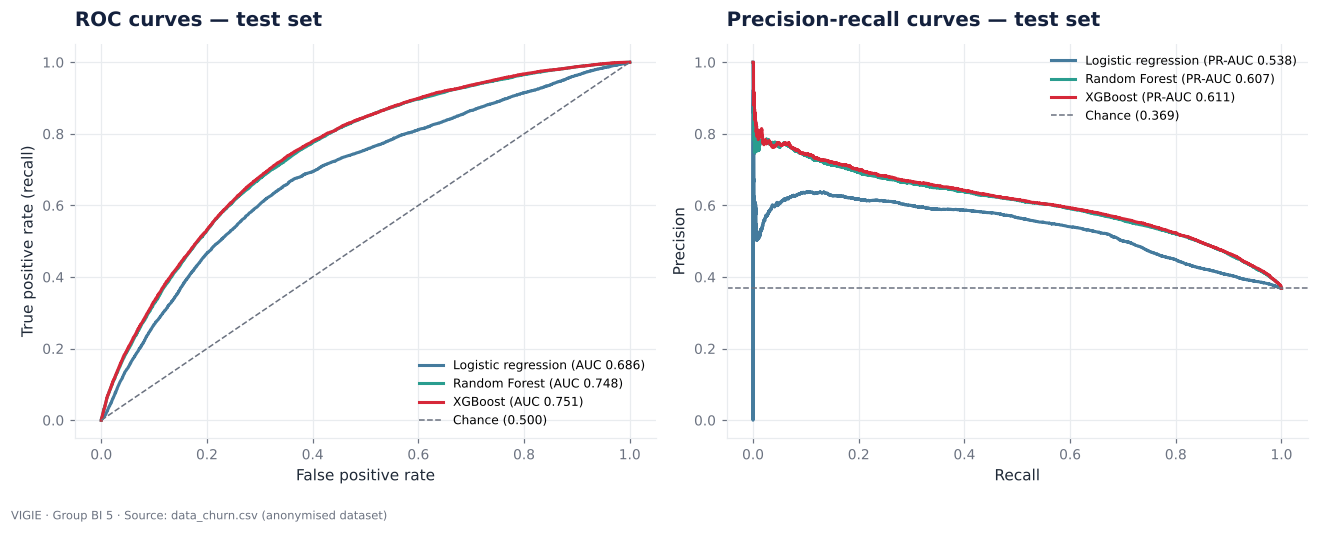

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
palette = {"Logistic regression": C["sky"], "Random Forest": C["retention"], "XGBoost": C["churn"]}
for name, color in palette.items():
    fpr, tpr, _ = roc_curve(y[te], probas[name])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {comparison.loc[name, 'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y[te], probas[name])
    axes[1].plot(rc, pr, color=color, lw=2, label=f"{name} (PR-AUC {comparison.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1, label="Chance (0.500)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves — test set")
axes[1].axhline(y[te].mean(), color=C["grey"], ls="--", lw=1, label=f"Chance ({y[te].mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves — test set")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8)
fig.tight_layout()
style.save(fig, "04_churn_roc_pr")
plt.show()

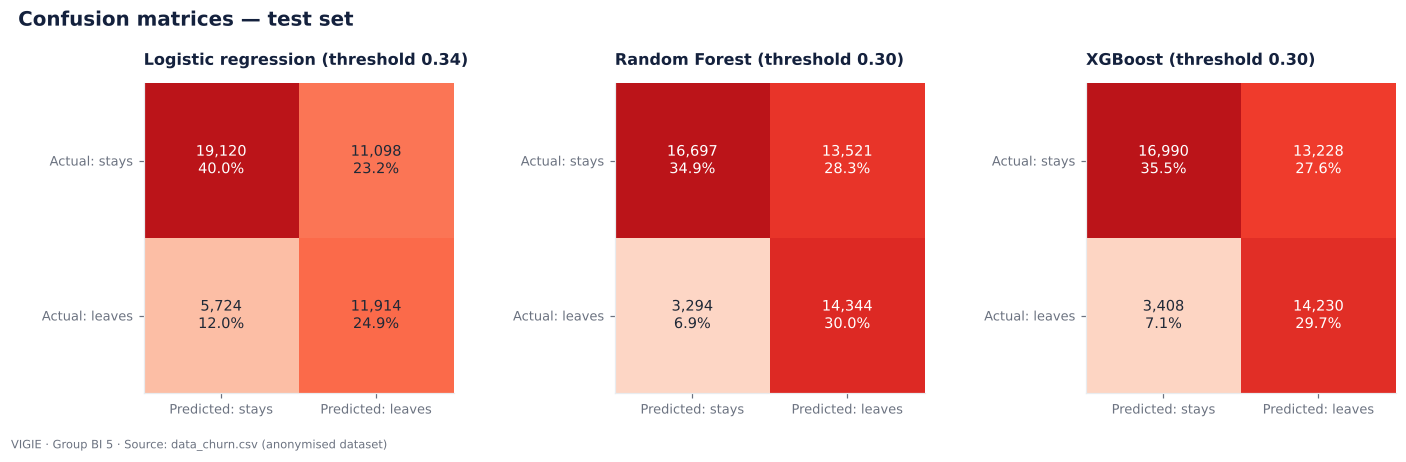

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, name in zip(axes, palette):
    r = comparison.loc[name]
    matrix = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]], dtype=float)
    ax.imshow(matrix, cmap="Reds", vmin=0, vmax=matrix.max() * 1.25)
    for (i, j), v in np.ndenumerate(matrix):
        ax.text(j, i, f"{n(v)}\n{v / matrix.sum():.1%}", ha="center", va="center", fontsize=9.5,
                color="white" if v > matrix.max() * 0.7 else C["text"])
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Predicted: stays", "Predicted: leaves"], fontsize=8.5)
    ax.set_yticklabels(["Actual: stays", "Actual: leaves"], fontsize=8.5)
    ax.set_title(f"{name} (threshold {r['Threshold']:.2f})", fontsize=10.5)
    ax.grid(False)
fig.suptitle("Confusion matrices — test set", x=0.01, ha="left", fontweight="bold", color=C["ink"], fontsize=13)
fig.tight_layout()
style.save(fig, "04_churn_confusion_matrices")
plt.show()

**Reading — model comparison** (test set, 47,856 customers).

* **All three models beat the baseline by far**: the PR-AUC goes from 0.37 (the churn rate) to 0.54–0.61.
* **Tree-based models dominate logistic regression**: +0.06 of ROC-AUC. This was expected from the bivariate
  analysis: age and tenure have a "bell-shaped" effect that a linear model cannot follow.
* **XGBoost and Random Forest are neck and neck** (0.751 against 0.748 of ROC-AUC); XGBoost is slightly ahead on
  every metric.
* **At the chosen threshold (≈ 0.30)**, XGBoost spots **81% of the customers who leave** (recall), with a
  precision of 52%: one flagged customer in two actually leaves, whereas the base rate is 37%.
* **Accuracy (65%) is misleading**: the baseline that predicts "nobody leaves" already reaches 63%, while
  detecting no departure at all. This is why a churn model is not judged on accuracy.

**Why a threshold of 0.30 rather than 0.50?** Missing a customer who leaves costs more than wrongly contacting a
loyal one. The threshold that maximises F1 on the validation set therefore favours recall. This threshold is a
business setting: it can be moved according to the budget of the retention campaign.

## 6. Hyperparameter tuning

Random search on XGBoost: 12 combinations, evaluated by **3-fold cross-validation, per customer**
(`GroupKFold`), on the training set only. Criterion: PR-AUC.

In [12]:
best_params, search = churn.tune_xgboost(X.iloc[tr], y[tr], groups[tr])
preview = search.head(5).copy()
preview["params"] = preview["params"].map(lambda p: ", ".join(f"{k}={v}" for k, v in sorted(p.items())))
preview.columns = ["Rank", "Mean PR-AUC (3 folds)", "Std dev", "Hyperparameters"]
pd.set_option("display.max_colwidth", 200)
display(preview.round(4).set_index("Rank"))
print(f"PR-AUC of the worst combination: {search['mean_test_score'].min():.4f}   |   "
      f"of the best: {search['mean_test_score'].max():.4f}")
print("Hyperparameters kept:", best_params)

final = churn.xgboost(**best_params).fit(X.iloc[tr], y[tr])
p_va, p_te = final.predict_proba(X.iloc[va])[:, 1], final.predict_proba(X.iloc[te])[:, 1]
final_threshold = churn.f1_threshold(y[va], p_va)
final_metrics = churn.evaluate(y[te], p_te, final_threshold)
before_after = pd.DataFrame({"Default XGBoost": comparison.loc["XGBoost"], "Tuned XGBoost": final_metrics}).T
display(before_after[metric_columns].astype(float).round(4))

# Stability: does the model over-fit?
stability = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y[i], final.predict_proba(X.iloc[i])[:, 1])}
    for name, i in (("Training", tr), ("Validation", va), ("Test", te))}).T
display(stability.round(4))

,Mean PR-AUC (3 folds),Std dev,Hyperparameters
Rank,,,
1,0.6133,0.0040,"colsample_bytree=0.8, learning_rate=0.05, max_depth=7, min_child_weight=1, n_estimators=300, reg_lambda=1, subsample=0.9"
2,0.6131,0.0042,"colsample_bytree=0.6, learning_rate=0.03, max_depth=8, min_child_weight=5, n_estimators=600, reg_lambda=10, subsample=0.7"
3,0.6129,0.0041,"colsample_bytree=0.8, learning_rate=0.05, max_depth=8, min_child_weight=1, n_estimators=200, reg_lambda=10, subsample=0.9"
4,0.6127,0.0043,"colsample_bytree=0.8, learning_rate=0.05, max_depth=8, min_child_weight=20, n_estimators=300, reg_lambda=10, subsample=0.9"
5,0.6122,0.0040,"colsample_bytree=1.0, learning_rate=0.12, max_depth=6, min_child_weight=20, n_estimators=300, reg_lambda=10, subsample=1.0"


PR-AUC of the worst combination: 0.6102   |   of the best: 0.6133
Hyperparameters kept: {'subsample': 0.9, 'reg_lambda': 1, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
Default XGBoost,0.7507,0.6112,0.5182,0.8068,0.6311,0.6524,0.1916,0.2982
Tuned XGBoost,0.7508,0.6113,0.5264,0.7901,0.6318,0.6607,0.1915,0.3182


,ROC-AUC
Training,0.7679
Validation,0.7518
Test,0.7508


**Reading — tuning.**

* **Tuning changes the result very little.** Between the worst and the best of the 12 combinations, the PR-AUC
  only varies from 0.610 to 0.613; on the test set, the tuned model is level with the default one (ROC-AUC 0.7508
  against 0.7507). **The ceiling comes from the information held in the features, not from the tuning.**
* The tuned model is kept because it is very slightly better calibrated (Brier 0.1915) and because its
  parameters were validated by cross-validation.
* **Little over-fitting**: ROC-AUC of 0.768 on training, 0.752 on validation, 0.751 on test. The announced
  performance is therefore reliable on new customers.

## 7. Sensitivity analysis: what is each family of features worth?

The same XGBoost is re-trained after removing or adding groups of features. This answers two questions:
*where does the performance come from?* and *would the discarded features have helped?*

In [13]:
fam = features.feature_families()
all_columns = list(X.columns)
candidates = features.discarded_candidates(customers)            # industry and branch group, encoded
X_wide = pd.concat([X, candidates], axis=1)

scenarios = {
    "Model kept (12 features)": (X, all_columns),
    "+ industry and branch group (14 features)": (X_wide, list(X_wide.columns)),
    "Without the two review features": (X, [c for c in all_columns if "REVIEW" not in c]),
    "Without the Compliance family": (X, features.columns_of(fam["Demographics"] + fam["Relationship"])),
    "Compliance only": (X, features.columns_of(fam["Compliance"])),
    "Relationship only": (X, features.columns_of(fam["Relationship"])),
    "Demographics only": (X, features.columns_of(fam["Demographics"])),
}
rows = {}
for name, (matrix, cols) in scenarios.items():
    m = churn.xgboost(**best_params).fit(matrix.iloc[tr][cols], y[tr])
    p = m.predict_proba(matrix.iloc[te][cols])[:, 1]
    rows[name] = {"Columns": len(cols), "ROC-AUC": roc_auc_score(y[te], p), "PR-AUC": average_precision_score(y[te], p)}
sensitivity = pd.DataFrame(rows).T
sensitivity["ROC-AUC gap"] = sensitivity["ROC-AUC"] - sensitivity.loc["Model kept (12 features)", "ROC-AUC"]
display(sensitivity.round(4))

,Columns,ROC-AUC,PR-AUC,ROC-AUC gap
Model kept (12 features),31.0,0.7508,0.6113,0.0000
+ industry and branch group (14 features),65.0,0.7563,0.6253,0.0054
Without the two review features,29.0,0.7302,0.5934,-0.0207
Without the Compliance family,22.0,0.6603,0.5054,-0.0905
Compliance only,9.0,0.7156,0.5727,-0.0352
Relationship only,11.0,0.6280,0.4702,-0.1228
Demographics only,11.0,0.5812,0.4263,-0.1696


**Reading — sensitivity.**

* **Compliance carries most of the signal.** On its own it reaches a ROC-AUC of 0.716; without it the model
  falls to 0.660. The commercial relationship alone gives 0.628 and demographics alone 0.581.
* **The three families complement each other**: together (0.751) they do better than the best one alone.
* **Without the two review features**, the model loses 0.02 of AUC (0.730): they matter, but the model does not
  rest on them alone.
* **Industry and branch group** would bring +0.006 of ROC-AUC and +0.014 of PR-AUC, at the cost of 34 extra
  columns. We choose **not to keep them**: branch groups are anonymous codes with no meaning for a profile typed
  by hand, and the gain does not justify doubling the size of the model. It is a deliberate trade-off between
  performance and simplicity; the branch remains an analysis axis of the dashboard.

⚠ **Reservation about the compliance features.** A file that is not reviewed may precede the departure (a
neglected customer) or follow it (the file of a customer who has left is no longer reviewed). The dataset, which
is a single snapshot, cannot settle the question. We keep them, as the guide recommends, and give here the exact
measure of their weight: **the model is worth 0.751 with them and 0.660 without them.** The operational truth
lies between the two.

## 8. Calibration and gains curve

**Calibration.** When the model says 60%, do 60% of the customers concerned actually leave? This is essential
here, since the application displays the probability itself.

**Gains.** If only part of the customers can be contacted, what share of the departures is reached by starting
with the highest scores?

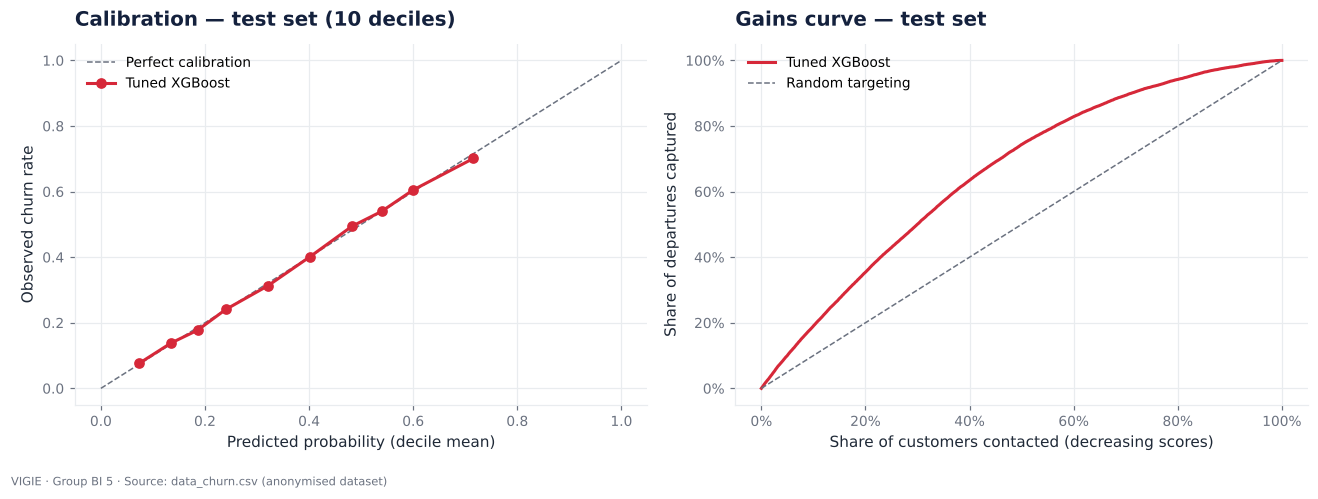

Score decile,1,2,3,4,5,6,7,8,9,10
Mean predicted probability,0.073,0.135,0.186,0.240,0.321,0.402,0.482,0.539,0.600,0.716
Observed churn rate,0.076,0.138,0.177,0.240,0.313,0.402,0.494,0.539,0.605,0.701
Gap,0.003,0.003,-0.008,0.001,-0.008,-0.000,0.012,0.000,0.005,-0.015


Customers targeted,Departures captured,Churn rate in the target,Lift
5%,10.0%,73.9%,2.00
10%,19.0%,70.1%,1.90
20%,35.4%,65.3%,1.77
30%,50.1%,61.5%,1.67
50%,74.4%,54.8%,1.49


   Customers targeted  Departures captured  Churn rate in the target   Lift
0                0.05                0.100                     0.739  2.005
1                0.10                0.190                     0.701  1.902
2                0.20                0.354                     0.653  1.771
3                0.30                0.501                     0.615  1.668
4                0.50                0.744                     0.548  1.487


In [14]:
observed_fraction, mean_probability = calibration_curve(y[te], p_te, n_bins=10, strategy="quantile")
gains = churn.gains(y[te], p_te)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1, label="Perfect calibration")
axes[0].plot(mean_probability, observed_fraction, color=C["churn"], marker="o", lw=2, label="Tuned XGBoost")
axes[0].set_xlabel("Predicted probability (decile mean)")
axes[0].set_ylabel("Observed churn rate")
axes[0].set_title("Calibration — test set (10 deciles)")
axes[0].legend()
order = np.argsort(-p_te)
cumulative = np.cumsum(y[te][order]) / y[te].sum()
share = np.arange(1, len(order) + 1) / len(order)
axes[1].plot(share, cumulative, color=C["churn"], lw=2, label="Tuned XGBoost")
axes[1].plot([0, 1], [0, 1], color=C["grey"], ls="--", lw=1, label="Random targeting")
axes[1].xaxis.set_major_formatter(style.percent)
axes[1].yaxis.set_major_formatter(style.percent)
axes[1].set_xlabel("Share of customers contacted (decreasing scores)")
axes[1].set_ylabel("Share of departures captured")
axes[1].set_title("Gains curve — test set")
axes[1].legend()
fig.tight_layout()
style.save(fig, "04_churn_calibration_gains")
plt.show()

calibration = pd.DataFrame({"Mean predicted probability": mean_probability, "Observed churn rate": observed_fraction},
                           index=pd.RangeIndex(1, 11, name="Score decile"))
calibration["Gap"] = calibration["Observed churn rate"] - calibration["Mean predicted probability"]
display(calibration.round(3).T)
display(gains.style.format({"Customers targeted": "{:.0%}", "Departures captured": "{:.1%}",
                            "Churn rate in the target": "{:.1%}", "Lift": "{:.2f}"}).hide(axis="index"))
print(gains.round(3).to_string())

**Reading — calibration.** The curve follows the diagonal: in every decile, the observed churn rate is within
1.5 points of the announced probability. **A score of 60% does mean that about 6 customers in 10 with that
profile left.** The probability can therefore be displayed as is in the application, with no recalibration.

**Reading — gains.** The score makes it possible to focus the commercial effort:

* by contacting the **10%** best-scored customers, we reach **19%** of the departures, and 70% of the customers
  contacted are indeed leavers;
* with **20%** of the customers, we reach **35%** of the departures (65% of leavers among those contacted, i.e.
  1.8 times better than random targeting);
* with **30%** of the customers, we reach **half** of the departures.

## 9. Interpretability

### 9.1 Feature importance

Two complementary measures, brought back to the business feature (the indicator columns of the same feature are
added up):

* **Gain** (XGBoost's native importance): share of the model's improvement due to the splits made on the feature.
* **SHAP**: mean absolute contribution of the feature to the prediction of each customer.

,Gain (share),Mean absolute SHAP,SHAP (share)
Months to next review,20.0%,0.484,34.2%
Months since last review,40.0%,0.262,18.5%
Customer tenure (years),10.0%,0.167,11.8%
Age,11.5%,0.155,11.0%
Number of accounts,7.2%,0.077,5.5%
KYC score,3.2%,0.069,4.8%
Complete file,0.4%,0.061,4.3%
Declared income,2.1%,0.043,3.0%
Marital status,1.8%,0.036,2.6%
Commercial segment,1.3%,0.022,1.6%


                          Gain (share)  Mean absolute SHAP  SHAP (share)
Months to next review            0.200               0.484         0.342
Months since last review         0.400               0.262         0.185
Customer tenure (years)          0.100               0.167         0.118
Age                              0.115               0.155         0.110
Number of accounts               0.072               0.077         0.055
KYC score                        0.032               0.069         0.048
Complete file                    0.004               0.061         0.043
Declared income                  0.021               0.043         0.030
Marital status                   0.018               0.036         0.026
Commercial segment               0.013               0.022         0.016
Customer type                    0.010               0.022         0.015
Residence zone                   0.016               0.018         0.012


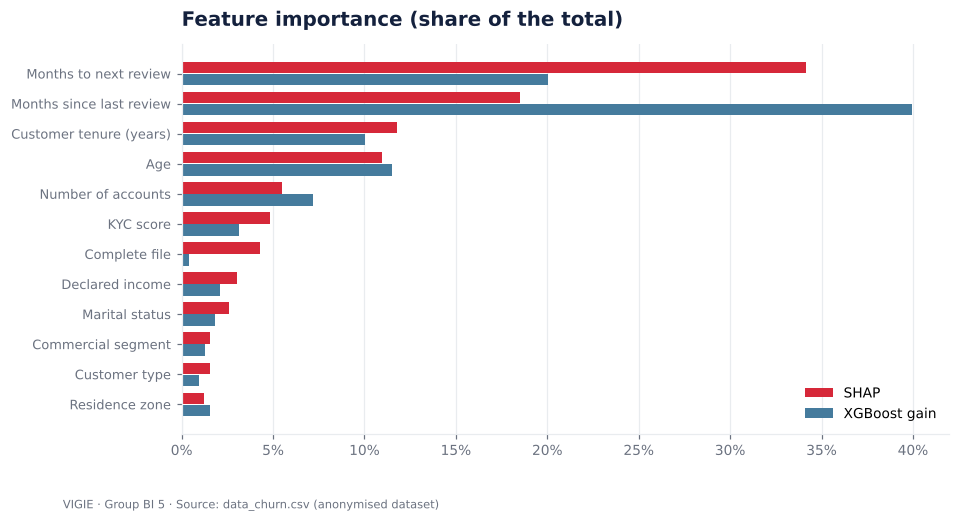

In [15]:
sample = np.random.default_rng(config.SEED).choice(te, size=5000, replace=False)
explainer = shap.TreeExplainer(final)
shap_values = explainer.shap_values(X.iloc[sample])

gain = pd.Series(final.get_booster().get_score(importance_type="total_gain")).reindex(X.columns).fillna(0)
by_feature = lambda s: s.groupby([preprocessing.source_feature(c) for c in s.index]).sum()  # noqa: E731
importance = pd.DataFrame({
    "Gain (share)": by_feature(gain) / gain.sum(),
    "Mean absolute SHAP": by_feature(pd.Series(np.abs(shap_values).mean(axis=0), index=X.columns)),
})
importance["SHAP (share)"] = importance["Mean absolute SHAP"] / importance["Mean absolute SHAP"].sum()
importance.index = [preprocessing.LABELS[v] for v in importance.index]
importance = importance.sort_values("SHAP (share)", ascending=False)
display(importance.style.format({"Gain (share)": "{:.1%}", "Mean absolute SHAP": "{:.3f}", "SHAP (share)": "{:.1%}"}))
print(importance.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.6))
i = importance.iloc[::-1]
pos = np.arange(len(i))
ax.barh(pos + 0.2, i["SHAP (share)"], height=0.38, color=C["churn"], label="SHAP")
ax.barh(pos - 0.2, i["Gain (share)"], height=0.38, color=C["sky"], label="XGBoost gain")
ax.set_yticks(pos)
ax.set_yticklabels(i.index, fontsize=8.5)
ax.xaxis.set_major_formatter(style.percent)
ax.set_title("Feature importance (share of the total)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
style.save(fig, "04_churn_importance")
plt.show()

**Reading — importance.** Both measures put the same features at the top, in a slightly different order.

* The **two review features** together weigh 53% of the SHAP importance (60% of the gain).
* Then come **tenure** (12%), **age** (11%) and the **number of accounts** (5%).
* The four **compliance** features together account for 62% of the SHAP importance.
* Segment, customer type and residence zone each weigh less than 2%: churn hardly depends on the commercial segment.

### 9.2 SHAP values: which way does each feature push?

Each dot is a customer of the test set. To the right of the axis, the feature **raises** their risk of leaving;
to the left, it **lowers** it. The colour shows whether the value of the feature is low (blue) or high (red).

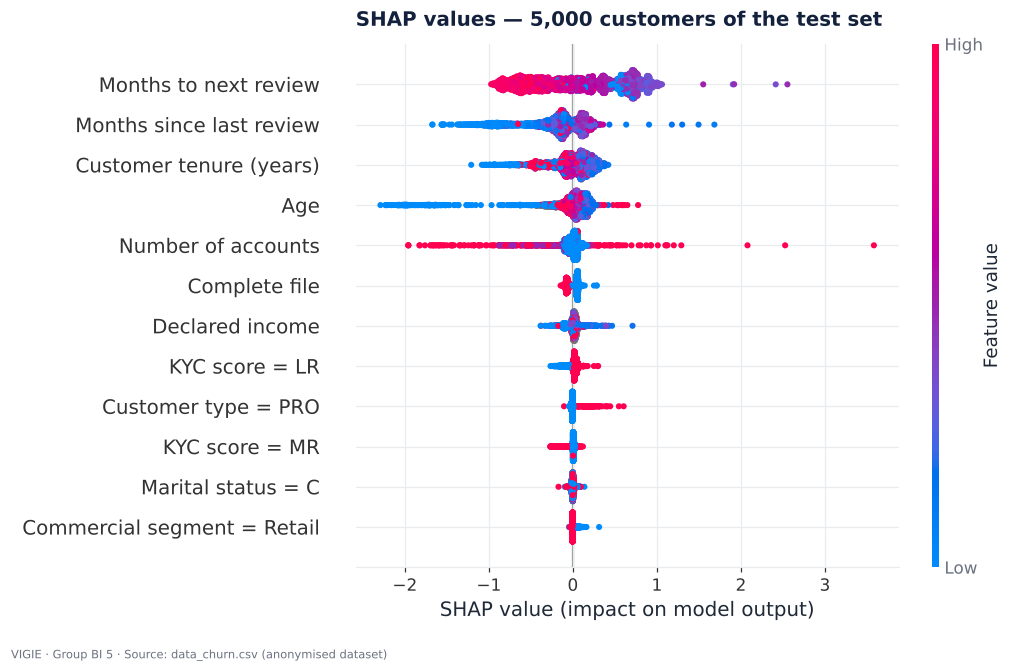

In [16]:
readable = [c if "=" not in c else f"{preprocessing.LABELS[c.split('=')[0]]} = {c.split('=')[1]}" for c in X.columns]
readable = [preprocessing.LABELS.get(r, r) for r in readable]
shap.summary_plot(shap_values, X.iloc[sample], feature_names=readable, max_display=12, show=False, plot_size=(9.5, 5.6))
fig = plt.gcf()
plt.title("SHAP values — 5,000 customers of the test set", loc="left", fontweight="bold", color=C["ink"])
style.save(fig, "04_churn_shap_summary")
plt.show()

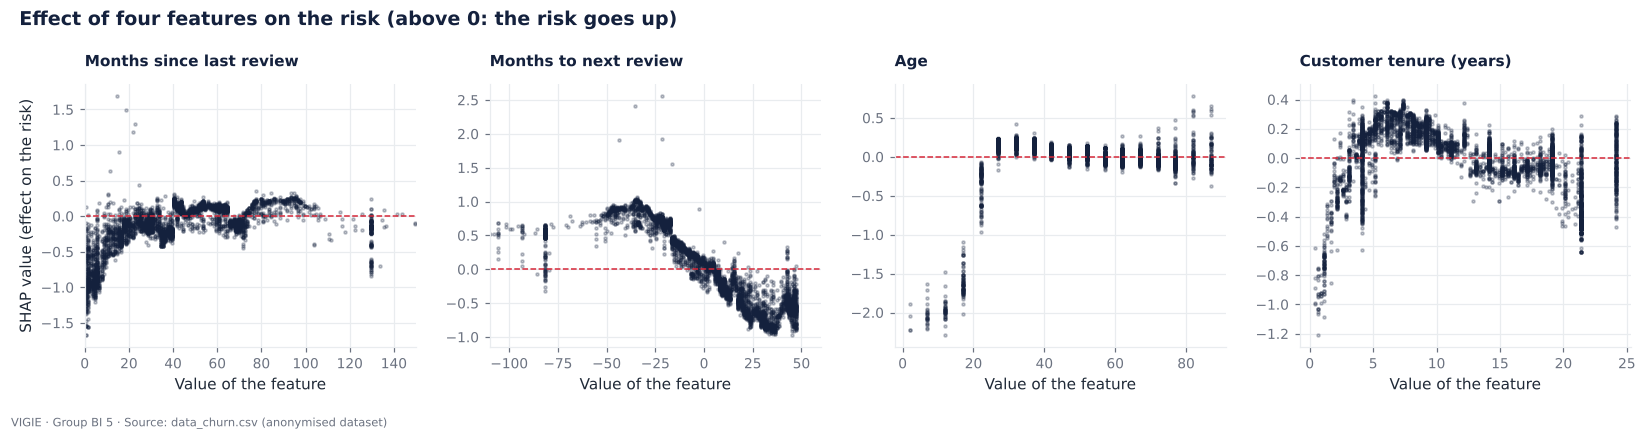

,Mean SHAP effect (log-odds)
Review overdue (months to next review < 0),0.528
Review to come (months to next review ≥ 0),-0.418
Last review more than 5 years ago,-0.052
Last review less than 2 years ago,-0.525
Under 25,-1.134
25 to 44,0.136
Tenure under 3 years,-0.432
Tenure of 5 to 10 years,0.198
A single account,0.001
Two accounts or more,-0.202


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
Xs = X.iloc[sample]
for ax, col in zip(axes, ["MONTHS_SINCE_REVIEW", "MONTHS_TO_NEXT_REVIEW", "AGE", "CUSTOMER_TENURE"]):
    j = list(X.columns).index(col)
    ax.scatter(Xs[col], shap_values[:, j], s=4, alpha=0.25, color=C["ink"])
    ax.axhline(0, color=C["churn"], lw=1, ls="--")
    ax.set_title(preprocessing.LABELS[col], fontsize=10)
    ax.set_xlabel("Value of the feature")
axes[0].set_ylabel("SHAP value (effect on the risk)")
axes[0].set_xlim(0, 150)
axes[1].set_xlim(-110, 60)
fig.suptitle("Effect of four features on the risk (above 0: the risk goes up)", x=0.01, ha="left",
             fontweight="bold", color=C["ink"], fontsize=12.5)
fig.tight_layout()
style.save(fig, "04_churn_shap_dependence")
plt.show()

# A few figures to help read the charts.
def mean_effect(col, mask):
    return float(shap_values[mask.to_numpy(), list(X.columns).index(col)].mean())


markers = pd.Series({
    "Review overdue (months to next review < 0)": mean_effect("MONTHS_TO_NEXT_REVIEW", Xs["MONTHS_TO_NEXT_REVIEW"] < 0),
    "Review to come (months to next review ≥ 0)": mean_effect("MONTHS_TO_NEXT_REVIEW", Xs["MONTHS_TO_NEXT_REVIEW"] >= 0),
    "Last review more than 5 years ago": mean_effect("MONTHS_SINCE_REVIEW", Xs["MONTHS_SINCE_REVIEW"] > 60),
    "Last review less than 2 years ago": mean_effect("MONTHS_SINCE_REVIEW", Xs["MONTHS_SINCE_REVIEW"] < 24),
    "Under 25": mean_effect("AGE", Xs["AGE"] < 25),
    "25 to 44": mean_effect("AGE", (Xs["AGE"] >= 25) & (Xs["AGE"] < 45)),
    "Tenure under 3 years": mean_effect("CUSTOMER_TENURE", Xs["CUSTOMER_TENURE"] < 3),
    "Tenure of 5 to 10 years": mean_effect("CUSTOMER_TENURE", (Xs["CUSTOMER_TENURE"] >= 5) & (Xs["CUSTOMER_TENURE"] < 10)),
    "A single account": mean_effect("N_ACCOUNTS", Xs["N_ACCOUNTS"] == 1),
    "Two accounts or more": mean_effect("N_ACCOUNTS", Xs["N_ACCOUNTS"] >= 2),
    "Complete file": mean_effect("FILE_COMPLETE", Xs["FILE_COMPLETE"] == 1),
    "Incomplete file": mean_effect("FILE_COMPLETE", Xs["FILE_COMPLETE"] == 0),
}, name="Mean SHAP effect (log-odds)")
display(markers.round(3).to_frame())

**Reading — the direction of the effects** (mean SHAP values; positive = the risk goes up).

| Factor | Effect | Business reading |
|---|---:|---|
| Next review **overdue** | **+0.53** | the first warning sign: a file that is no longer followed |
| Next review to come | −0.42 | a customer whose follow-up is up to date is clearly less at risk |
| Last review less than 2 years ago | −0.53 | a recent review protects |
| Last review more than 5 years ago | −0.05 | weak effect of its own: the information is already carried by the overdue next review |
| Under 25 | −1.13 | the youngest leave very little |
| 25 to 44 | +0.14 | the most mobile age group |
| Tenure under 3 years | −0.43 | recent relationship (and not yet the time to leave) |
| Tenure of 5 to 10 years | +0.20 | the fragile zone of the relationship |
| Two accounts or more | −0.20 | on average, holding several accounts builds loyalty (the effect varies with the profile) |
| Incomplete / complete file | +0.05 / −0.07 | modest effect of its own once the reviews are taken into account |

The dependence plots confirm the shapes seen in the bivariate analysis: a **bell-shaped** effect of age and
tenure, and a **sharp step at zero** for the delay before the next review (as soon as the review is overdue, the
risk tips over).

## 10. Final model, export and limitations

### 10.1 From the score to the risk level

For the application, the score is translated into three levels, whose actual content is checked here on the test set.

In [18]:
# Score → observed rate table (on the test set), displayed in the application
bands = pd.cut(p_te, bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
score_table = pd.DataFrame({"y": y[te], "band": bands}).groupby("band", observed=True)["y"].agg(["size", "mean"])
score_table.columns = ["Test customers", "Observed churn rate"]
display(score_table.style.format({"Test customers": n, "Observed churn rate": "{:.1%}"}))

levels = pd.cut(p_te, bins=[0, 0.25, 0.50, 1.0], labels=["Low (< 25%)", "Moderate (25–50%)", "High (≥ 50%)"],
                include_lowest=True, right=False)
level_table = pd.DataFrame({"y": y[te], "level": levels}).groupby("level", observed=True)["y"].agg(["size", "mean"])
level_table["share"] = level_table["size"] / level_table["size"].sum()
level_table.columns = ["Test customers", "Observed churn rate", "Share of customers"]
display(level_table.style.format({"Test customers": n, "Observed churn rate": "{:.1%}", "Share of customers": "{:.1%}"}))
print(level_table.round(3).to_string())

,Test customers,Observed churn rate
band,,
"(-0.001, 0.1]","3,871",7.3%
"(0.1, 0.2]","9,422",14.6%
"(0.2, 0.3]","7,176",24.5%
"(0.3, 0.4]","5,956",35.0%
"(0.4, 0.5]","5,929",45.7%
"(0.5, 0.6]","8,383",55.3%
"(0.6, 0.7]","4,410",63.4%
"(0.7, 0.8]","2,550",73.3%
"(0.8, 1.0]",159,81.1%


,Test customers,Observed churn rate,Share of customers
level,,,
Low (< 25%),"17,707",15.0%,37.0%
Moderate (25–50%),"14,647",37.9%,30.6%
High (≥ 50%),"15,502",60.9%,32.4%


                   Test customers  Observed churn rate  Share of customers
level                                                                     
Low (< 25%)                 17707                0.150               0.370
Moderate (25–50%)           14647                0.379               0.306
High (≥ 50%)                15502                0.609               0.324


The three levels are well separated: **15%** of observed departures in the low level, **38%** in the moderate
level, **61%** in the high level. Each level gathers about a third of the customers.

### 10.2 Model kept: tuned XGBoost

| Criterion | Logistic regression | Random Forest | **XGBoost** |
|---|---|---|---|
| ROC-AUC / PR-AUC | 0.686 / 0.538 | 0.748 / 0.607 | **0.751 / 0.611** |
| Calibration (Brier, lower is better) | 0.209 | 0.193 | **0.192** |
| Missing values | imputation needed | imputation needed | **handled natively** |
| Export without data | coefficients | large `.pkl` file | **trees in readable JSON (3 MB)** |
| Explaining one prediction | coefficients | approximate | **exact SHAP, immediate** |

XGBoost is kept: it is the best performer, the best calibrated, and it is the only one of the two tree models
that can be exported to a text format **holding no observation**, which makes it possible to deploy it while
respecting the rule "no data in the repository".

### 10.3 Limitations

1. **Moderate performance (ROC-AUC 0.75).** A customer's profile explains part of churn, not all of it. What is
   missing is *behavioural* data (transactions, complaints, contacts), which usually announce a departure.
2. **A snapshot, not a film.** The features are observed at the reference date, sometimes after the closure. For
   the compliance features, it cannot be ruled out that they partly reflect the departure.
3. **Recent customers.** Their low churn rate is also due to the fact that they have not yet had time to leave.
4. **Mass operations.** Half of the closures come from five batch operations: part of the "departures" learnt by
   the model is a management decision, not a choice of the customer.
5. **Use.** The score is meant to **prioritise** a retention action, not to decide a customer's fate on its own.

In [19]:
# Saving
config.MODELS.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": final, "columns": list(X.columns), "threshold": final_threshold},
            config.MODELS / "final_model.pkl")                         # outside the repository (.gitignore)

config.APP_ARTIFACTS.mkdir(parents=True, exist_ok=True)
final.get_booster().save_model(config.APP_ARTIFACTS / "churn_model.json")   # trees only, readable
all_models = {**comparison.to_dict(orient="index"), "Tuned XGBoost (kept)": final_metrics}
meta = {
    "model": "XGBoost (gradient boosting of decision trees)",
    "grain": "customer", "target": "all of the customer's accounts are closed",
    "reference_date": str(ref_date.date()),
    "source_sha256": data.fingerprint()["sha256"],
    "training": {"train_customers": int(len(tr)), "validation_customers": int(len(va)), "test_customers": int(len(te)),
                 "split": "GroupShuffleSplit per CUSTOMER_NO (70 / 15 / 15)", "seed": config.SEED,
                 "hyperparameters": {k: (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in best_params.items()}},
    "columns": list(X.columns),
    "base_rate": round(float(y[tr].mean()), 4),
    "shap_base_value": round(float(np.ravel(explainer.expected_value)[0]), 5),
    "alert_threshold": round(float(final_threshold), 4),
    "test_metrics": {k: (round(float(v), 4) if k not in ("TP", "FP", "FN", "TN") else int(v)) for k, v in final_metrics.items()},
    "model_comparison": {name: {k: round(float(v), 4) for k, v in row.items() if k in metric_columns}
                         for name, row in all_models.items()},
    "importance": {var: round(float(v), 4) for var, v in importance["SHAP (share)"].items()},
    "risk_levels": [{"level": str(lv), "test_customers": int(r["Test customers"]),
                     "observed_rate": round(float(r["Observed churn rate"]), 4)} for lv, r in level_table.iterrows()],
    "score_to_observed_rate": [{"from": round(float(b.left), 2) if b.left > 0 else 0.0, "to": round(float(b.right), 2),
                                "test_customers": int(r["Test customers"]), "observed_rate": round(float(r["Observed churn rate"]), 4)}
                               for b, r in score_table.iterrows()],
    "gains": gains.round(4).to_dict(orient="records"),
    "marginals": export_app.marginals(profiles, preprocessing.NUMERIC, preprocessing.CATEGORICAL),
}
export_app.write("churn_model_meta.json", meta)
export_app.write("kpi_summary.json", export_app.summary_aggregates(df, accounts, customers, data.load_references()))

ml_results = {
    "source_sha256": meta["source_sha256"],
    "model_comparison": meta["model_comparison"],
    "confusion_matrices": {name: {k: int(row[k]) for k in ("TP", "FP", "FN", "TN")} for name, row in all_models.items()},
    "hyperparameters": meta["training"]["hyperparameters"],
    "roc_auc_stability": stability["ROC-AUC"].round(4).to_dict(),
    "sensitivity": sensitivity.round(4).to_dict(orient="index"),
    "leakage_demonstration": demo["ROC-AUC on the test set"].round(4).to_dict(),
    "leakage_audit": audit.reset_index().to_dict(orient="records"),
    "importance": importance.round(4).reset_index(names="Feature").to_dict(orient="records"),
    "gains": meta["gains"], "risk_levels": meta["risk_levels"],
}
(config.ML_RESULTS / "churn_ml.json").write_text(json.dumps(ml_results, ensure_ascii=False, indent=1), encoding="utf-8")
size = (config.APP_ARTIFACTS / "churn_model.json").stat().st_size / 1e6
print("Full model   : 04_machine_learning/models/final_model.pkl (outside the repository)")
print(f"Trees (JSON) : 05_web_app/artifacts/churn_model.json ({size:.1f} MB, no observation)")
print("Metadata     : 05_web_app/artifacts/churn_model_meta.json")
print("Aggregates   : 05_web_app/artifacts/kpi_summary.json")
print("Results      : 04_machine_learning/results/churn_ml.json")

Full model   : 04_machine_learning/models/final_model.pkl (outside the repository)
Trees (JSON) : 05_web_app/artifacts/churn_model.json (3.0 MB, no observation)
Metadata     : 05_web_app/artifacts/churn_model_meta.json
Aggregates   : 05_web_app/artifacts/kpi_summary.json
Results      : 04_machine_learning/results/churn_ml.json
